In [4]:
pip install matplotlib networkx

Note: you may need to restart the kernel to use updated packages.


In [5]:
 pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [9]:
"""Part 1: Imports and Setting"""

'Part 1: Imports and Setting'

In [10]:
import csv
import gzip
import os
import random
import re
import shutil
import urllib.request
from collections import Counter

import matplotlib.pyplot as plt

from motifs import (
    triad_census,
    randomize,
    assert_degrees_preserved,
    z_scores
)

R = 2073
NUMBER_RANDOM_NETWORKS = 47
SWAP_FACTOR = 8
SEED = 2073

DATA_DIR = "data"
OUT_DIR = "results"

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

print("R:", R)
print("Random networks:", NUMBER_RANDOM_NETWORKS)
print("Swap factor:", SWAP_FACTOR)
print("Seed:", SEED)

R: 2073
Random networks: 47
Swap factor: 8
Seed: 2073


In [12]:
"""Part 2:Download dataset"""

'Part 2:Download dataset'

In [10]:
BASE_URL = "https://snap.stanford.edu/data/"

EDGE_FILE = "email-Eu-core.txt"
LABEL_FILE = "email-Eu-core-department-labels.txt"


def download_and_extract(filename):
    path = os.path.join(DATA_DIR, filename)

    if os.path.exists(path):
        print(filename, "already exists")
        return path

    compressed_path = path + ".gz"
    url = BASE_URL + filename + ".gz"

    print("Downloading:", filename)

    urllib.request.urlretrieve(url, compressed_path)

    with gzip.open(compressed_path, "rb") as source:
        with open(path, "wb") as destination:
            shutil.copyfileobj(source, destination)

    os.remove(compressed_path)

    return path


edge_path = download_and_extract(EDGE_FILE)
label_path = download_and_extract(LABEL_FILE)

email-Eu-core.txt already exists
email-Eu-core-department-labels.txt already exists


In [11]:
"""Part 3: Load and clean graph"""

'Load and clean graph'

In [13]:
edges = set()

with open(edge_path, "r") as file:
    for line in file:
        parts = line.split()

        if len(parts) < 2:
            continue

        u, v = int(parts[0]), int(parts[1])

        if u != v:
            edges.add((u, v))


labels = {}

with open(label_path, "r") as file:
    for line in file:
        parts = line.split()

        if len(parts) < 2:
            continue

        node, department = int(parts[0]), int(parts[1])
        labels[node] = department


print("Number of nodes:", len(labels))
print("Number of edges:", len(edges))
print("Number of departments:", len(set(labels.values())))

Number of nodes: 1005
Number of edges: 24929
Number of departments: 42


In [15]:
"""Part 4: Find top 20 department"""

'Find top 20 department'

In [14]:
internal_counts = Counter()

for u, v in edges:
    if u in labels and v in labels and labels[u] == labels[v]:
        internal_counts[labels[u]] += 1


top20 = sorted(
    internal_counts.items(),
    key=lambda item: (-item[1], item[0])
)[:20]


print("Top 20 Departments")

for rank, (department, count) in enumerate(top20, start=1):
    print(rank, "Department:", department, "Internal edges:", count)

Top 20 Departments
1 Department: 14 Internal edges: 1506
2 Department: 4 Internal edges: 1167
3 Department: 7 Internal edges: 679
4 Department: 21 Internal edges: 601
5 Department: 1 Internal edges: 502
6 Department: 10 Internal edges: 472
7 Department: 17 Internal edges: 441
8 Department: 0 Internal edges: 426
9 Department: 15 Internal edges: 357
10 Department: 11 Internal edges: 339
11 Department: 19 Internal edges: 306
12 Department: 13 Internal edges: 279
13 Department: 16 Internal edges: 236
14 Department: 36 Internal edges: 208
15 Department: 5 Internal edges: 147
16 Department: 9 Internal edges: 146
17 Department: 8 Internal edges: 134
18 Department: 22 Internal edges: 118
19 Department: 37 Internal edges: 99
20 Department: 20 Internal edges: 70


In [15]:
"""Part 5: Calculate assigned departments"""

'Calculate assigned departments'

In [16]:
pairs = [
    (i, j)
    for i in range(20)
    for j in range(i + 1, 20)
]

pair_number = R % 190

i, j = pairs[pair_number]

department_A = top20[i][0]
department_B = top20[j][0]

print("R:", R)
print("Pair number:", pair_number)
print("Department A:", department_A)
print("Department B:", department_B)
print("Random networks:", NUMBER_RANDOM_NETWORKS)
print("Swap factor:", SWAP_FACTOR)
print("Seed:", SEED)

R: 2073
Pair number: 173
Department A: 36
Department B: 37
Random networks: 47
Swap factor: 8
Seed: 2073


In [17]:
"""Part 6: Create department subgraphs"""

'Create department subgraphs'

In [18]:
def induced_subgraph(edges, labels, department):
    return {
        (u, v)
        for u, v in edges
        if labels.get(u) == department
        and labels.get(v) == department
    }


sub_A = induced_subgraph(edges, labels, department_A)
sub_B = induced_subgraph(edges, labels, department_B)

print("Department A edges:", len(sub_A))
print("Department B edges:", len(sub_B))

Department A edges: 208
Department B edges: 99


In [19]:
"""Part 7: Count real triads"""

'Count real triads'

In [20]:
real_A = triad_census(sub_A)
real_B = triad_census(sub_B)

print("Department A real triad counts")

for k in range(1, 14):
    print("Class", k, ":", real_A[k])

print("\nDepartment B real triad counts")

for k in range(1, 14):
    print("Class", k, ":", real_B[k])

Department A real triad counts
Class 1 : 42
Class 2 : 10
Class 3 : 199
Class 4 : 0
Class 5 : 8
Class 6 : 34
Class 7 : 39
Class 8 : 140
Class 9 : 0
Class 10 : 14
Class 11 : 4
Class 12 : 133
Class 13 : 187

Department B real triad counts
Class 1 : 17
Class 2 : 4
Class 3 : 61
Class 4 : 0
Class 5 : 4
Class 6 : 19
Class 7 : 17
Class 8 : 50
Class 9 : 0
Class 10 : 5
Class 11 : 3
Class 12 : 48
Class 13 : 40


In [21]:
"""PArt 8: Generate randomized networks"""

'Generate randomized networks'

In [22]:
def analyse_department(department_edges, number_random_networks, swap_factor, rng):
    real_counts = triad_census(department_edges)

    attempts = swap_factor * len(department_edges)

    null_counts = []

    for network_number in range(number_random_networks):
        network_seed = rng.randrange(2**32)

        randomized_edges = randomize(
            department_edges,
            attempts,
            network_seed
        )

        assert_degrees_preserved(
            department_edges,
            randomized_edges
        )

        counts = triad_census(randomized_edges)
        null_counts.append(counts)

        print(
            "Random network:",
            network_number + 1,
            "/",
            number_random_networks
        )

    z, means, standard_deviations = z_scores(
        real_counts,
        null_counts
    )

    return real_counts, null_counts, z, means, standard_deviations


rng = random.Random(SEED)

print("Department A")

results_A = analyse_department(
    sub_A,
    NUMBER_RANDOM_NETWORKS,
    SWAP_FACTOR,
    rng
)

print("\nDepartment B")

results_B = analyse_department(
    sub_B,
    NUMBER_RANDOM_NETWORKS,
    SWAP_FACTOR,
    rng
)

Department A
Random network: 1 / 47
Random network: 2 / 47
Random network: 3 / 47
Random network: 4 / 47
Random network: 5 / 47
Random network: 6 / 47
Random network: 7 / 47
Random network: 8 / 47
Random network: 9 / 47
Random network: 10 / 47
Random network: 11 / 47
Random network: 12 / 47
Random network: 13 / 47
Random network: 14 / 47
Random network: 15 / 47
Random network: 16 / 47
Random network: 17 / 47
Random network: 18 / 47
Random network: 19 / 47
Random network: 20 / 47
Random network: 21 / 47
Random network: 22 / 47
Random network: 23 / 47
Random network: 24 / 47
Random network: 25 / 47
Random network: 26 / 47
Random network: 27 / 47
Random network: 28 / 47
Random network: 29 / 47
Random network: 30 / 47
Random network: 31 / 47
Random network: 32 / 47
Random network: 33 / 47
Random network: 34 / 47
Random network: 35 / 47
Random network: 36 / 47
Random network: 37 / 47
Random network: 38 / 47
Random network: 39 / 47
Random network: 40 / 47
Random network: 41 / 47
Random netwo

In [23]:
"""Part 9: Save triad census CSV files"""

'Save triad census CSV files'

In [24]:
def save_census_csv(counts, department, filename):
    with open(filename, "w", newline="") as file:
        writer = csv.writer(file)

        writer.writerow(["Department", "Triad Class", "Count"])

        for k in range(1, 14):
            writer.writerow([department, k, counts[k]])


save_census_csv(
    results_A[0],
    department_A,
    os.path.join(OUT_DIR, "department_A_census.csv")
)

save_census_csv(
    results_B[0],
    department_B,
    os.path.join(OUT_DIR, "department_B_census.csv")
)

print("Census CSV files saved.")

Census CSV files saved.


In [25]:
"""Part 10: Save Z-scores"""

'Save Z-scores'

In [26]:
with open(os.path.join(OUT_DIR, "z_scores.csv"), "w", newline="") as file:
    writer = csv.writer(file)

    writer.writerow([
        "Department",
        "Triad Class",
        "Real Count",
        "Null Mean",
        "Null Std",
        "Z Score"
    ])

    for department, results in [
        (department_A, results_A),
        (department_B, results_B)
    ]:
        real, null, z, means, stds = results

        for k in range(1, 14):
            writer.writerow([
                department,
                k,
                real[k],
                means[k],
                stds[k],
                z[k]
            ])

print("Z-score CSV saved.")

Z-score CSV saved.


In [27]:
"""Part 11: Plot Z-score comparison"""

'Plot Z-score comparison'

In [28]:
import os

print(os.listdir("results"))

['T6_null_stats.csv', 'T2_deptB_nodes.csv', 'T7_zscores.png', 'motif_comparison.png', 'department_A_census.csv', 'T2_deptA_edges.csv', 'department_B_census.csv', 'T6_zscores.csv', 'T2_deptA_nodes.csv', 'T4_counts.csv', 'z_scores.csv', 'T1_parameters.txt', 'T2_deptB_edges.csv']


In [29]:
%matplotlib inline
import matplotlib.pyplot as plt

In [30]:
import random
import csv
import os
import matplotlib.pyplot as plt
from collections import Counter

from motifs import (
    triad_census,
    randomize,
    assert_degrees_preserved,
    z_scores
)

In [31]:
print("results_A:", "results_A" in globals())
print("results_B:", "results_B" in globals())
print("analyse_department:", "analyse_department" in globals())
print("sub_A:", "sub_A" in globals())
print("sub_B:", "sub_B" in globals())

results_A: True
results_B: True
analyse_department: True
sub_A: True
sub_B: True


In [32]:
rng = random.Random(SEED)

results_A = analyse_department(
    sub_A,
    NUMBER_RANDOM_NETWORKS,
    SWAP_FACTOR,
    rng
)

results_B = analyse_department(
    sub_B,
    NUMBER_RANDOM_NETWORKS,
    SWAP_FACTOR,
    rng
)

Random network: 1 / 47
Random network: 2 / 47
Random network: 3 / 47
Random network: 4 / 47
Random network: 5 / 47
Random network: 6 / 47
Random network: 7 / 47
Random network: 8 / 47
Random network: 9 / 47
Random network: 10 / 47
Random network: 11 / 47
Random network: 12 / 47
Random network: 13 / 47
Random network: 14 / 47
Random network: 15 / 47
Random network: 16 / 47
Random network: 17 / 47
Random network: 18 / 47
Random network: 19 / 47
Random network: 20 / 47
Random network: 21 / 47
Random network: 22 / 47
Random network: 23 / 47
Random network: 24 / 47
Random network: 25 / 47
Random network: 26 / 47
Random network: 27 / 47
Random network: 28 / 47
Random network: 29 / 47
Random network: 30 / 47
Random network: 31 / 47
Random network: 32 / 47
Random network: 33 / 47
Random network: 34 / 47
Random network: 35 / 47
Random network: 36 / 47
Random network: 37 / 47
Random network: 38 / 47
Random network: 39 / 47
Random network: 40 / 47
Random network: 41 / 47
Random network: 42 / 47
R

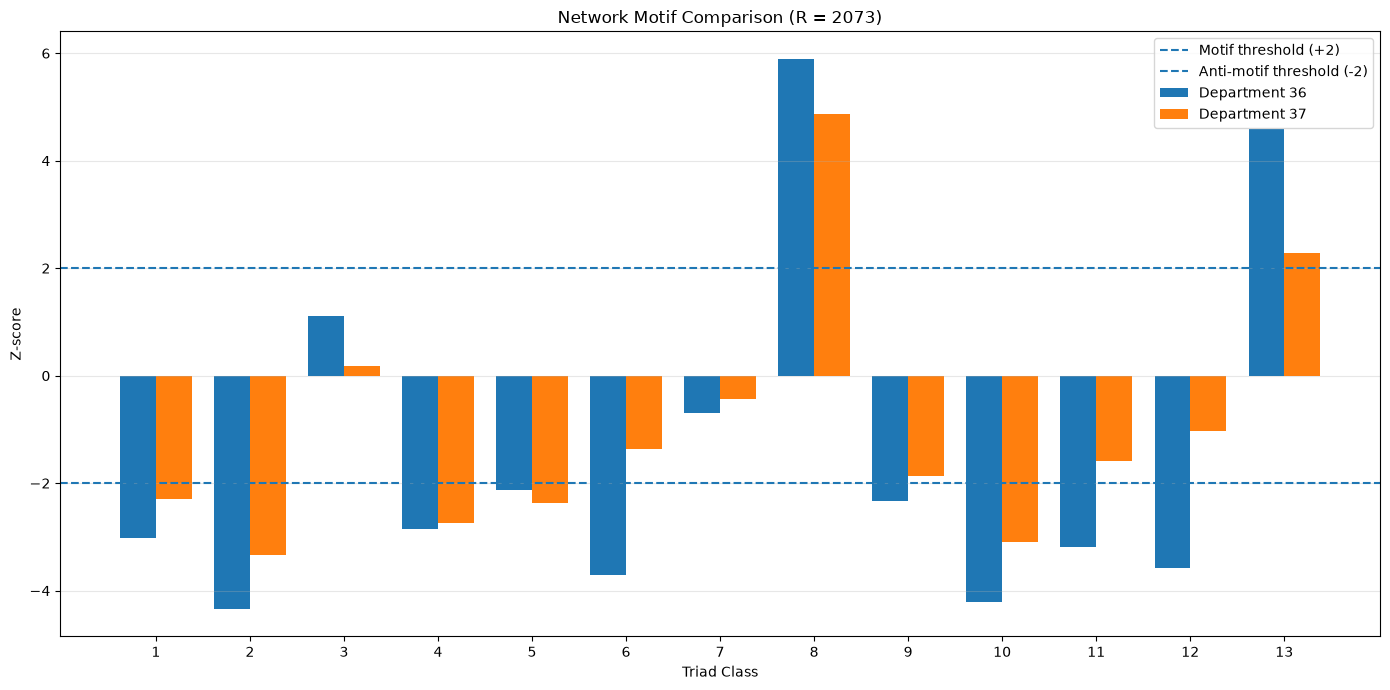

In [33]:
z_A = results_A[2]
z_B = results_B[2]

classes = list(range(1, 14))

values_A = [z_A[k] for k in classes]
values_B = [z_B[k] for k in classes]

x = list(range(13))
width = 0.38

plt.figure(figsize=(14, 7))

plt.bar(
    [v - width / 2 for v in x],
    values_A,
    width,
    label=f"Department {department_A}"
)

plt.bar(
    [v + width / 2 for v in x],
    values_B,
    width,
    label=f"Department {department_B}"
)

plt.axhline(2, linestyle="--", label="Motif threshold (+2)")
plt.axhline(-2, linestyle="--", label="Anti-motif threshold (-2)")

plt.xticks(x, classes)
plt.xlabel("Triad Class")
plt.ylabel("Z-score")
plt.title("Network Motif Comparison (R = 2073)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "motif_comparison.png"),
    dpi=300
)

plt.show()

In [34]:
"""Part 12: Display motif and anti-motif results"""

'Display motif and anti-motif results'

In [35]:
print("Department A:", department_A)

for k in range(1, 14):
    if z_A[k] > 2:
        print("Class", k, "is a MOTIF. Z-score:", z_A[k])
    elif z_A[k] < -2:
        print("Class", k, "is an ANTI-MOTIF. Z-score:", z_A[k])

print("\nDepartment B:", department_B)

for k in range(1, 14):
    if z_B[k] > 2:
        print("Class", k, "is a MOTIF. Z-score:", z_B[k])
    elif z_B[k] < -2:
        print("Class", k, "is an ANTI-MOTIF. Z-score:", z_B[k])

Department A: 36
Class 1 is an ANTI-MOTIF. Z-score: -3.0179905480018987
Class 2 is an ANTI-MOTIF. Z-score: -4.3414052905408065
Class 4 is an ANTI-MOTIF. Z-score: -2.85510308078465
Class 5 is an ANTI-MOTIF. Z-score: -2.120551939967469
Class 6 is an ANTI-MOTIF. Z-score: -3.713274412639727
Class 8 is a MOTIF. Z-score: 5.8955838926478235
Class 9 is an ANTI-MOTIF. Z-score: -2.3352929867802135
Class 10 is an ANTI-MOTIF. Z-score: -4.2169186562751415
Class 11 is an ANTI-MOTIF. Z-score: -3.18867346775505
Class 12 is an ANTI-MOTIF. Z-score: -3.5854390862492775
Class 13 is a MOTIF. Z-score: 4.580787388545127

Department B: 37
Class 1 is an ANTI-MOTIF. Z-score: -2.301375056093046
Class 2 is an ANTI-MOTIF. Z-score: -3.343735372753287
Class 4 is an ANTI-MOTIF. Z-score: -2.739280726912874
Class 5 is an ANTI-MOTIF. Z-score: -2.364334739626218
Class 8 is a MOTIF. Z-score: 4.870987243726343
Class 10 is an ANTI-MOTIF. Z-score: -3.098791677622991
Class 13 is a MOTIF. Z-score: 2.291162776497773
